<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/15-unsupervised-learning/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: Customer Groups for a Wholesale Distributor

A wholesale distributor in Portugal supplies 440 business customers: hotels, restaurants and cafés on one side, and shops on the other. For each customer, we know how much they spent in a year on six kinds of product. The distributor wants to understand its customers better: are there distinct **types** of customer, with different needs, that it could serve differently?

Nobody has labelled the customer types, so this is unsupervised learning. The dataset does record each customer's **channel** (hotel/restaurant/café or retail) and **region**, but we'll keep those aside and use them only at the end, to check whether the groups we find mean something the business would recognise.

The steps:

1. **Explore** the spending data, and see why it needs transforming
2. **Map** the customers with PCA
3. **Flag** unusual customers, and decide what to do with them
4. Choose the **number of groups** with several tools, including stability
5. **Describe** the groups in terms a sales team can use
6. **Check** the groups against the channel, and against other methods
7. Say honestly what the analysis can and can't support

## Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/15-unsupervised-learning/data/wholesale_customers.csv"
local = Path("data/wholesale_customers.csv")
raw = pd.read_csv(local if local.exists() else DATA_URL)
print(raw.shape)
raw.head()

(440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

Each row is one customer. The six spending columns are annual amounts in "monetary units" (the dataset doesn't say which currency). `Channel` and `Region` are numeric codes. The original file spells one column `Delicassen`; we'll call it `Delicatessen`, and decode the codes into words.

In [3]:
customers = raw.rename(columns={"Delicassen": "Delicatessen"})
customers["Channel"] = customers["Channel"].map({1: "Horeca", 2: "Retail"})
customers["Region"] = customers["Region"].map({1: "Lisbon", 2: "Oporto", 3: "Other"})
SPENDING = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]

print(customers["Channel"].value_counts().to_string())
print()
print(customers["Region"].value_counts().to_string())
print()
customers[SPENDING].describe().round(0)

Channel
Horeca    298
Retail    142

Region
Other     316
Lisbon     77
Oporto     47



,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


"Horeca" is the industry's name for hotels, restaurants and cafés. About two thirds of the customers are Horeca, and most are outside the two big cities. There are no missing values.

The spending columns are very skewed: in every category the mean is well above the median, and the largest customers spend 10 to 50 times as much as a typical one.

## Step 1: Explore, and transform

Clustering and PCA work with distances and variances, so a handful of giant customers would dominate everything. The usual fix for skewed amounts is the **logarithm** (Module 12): it turns "10 times as much" into "a fixed step more", so differences between small customers count as much as differences between large ones.

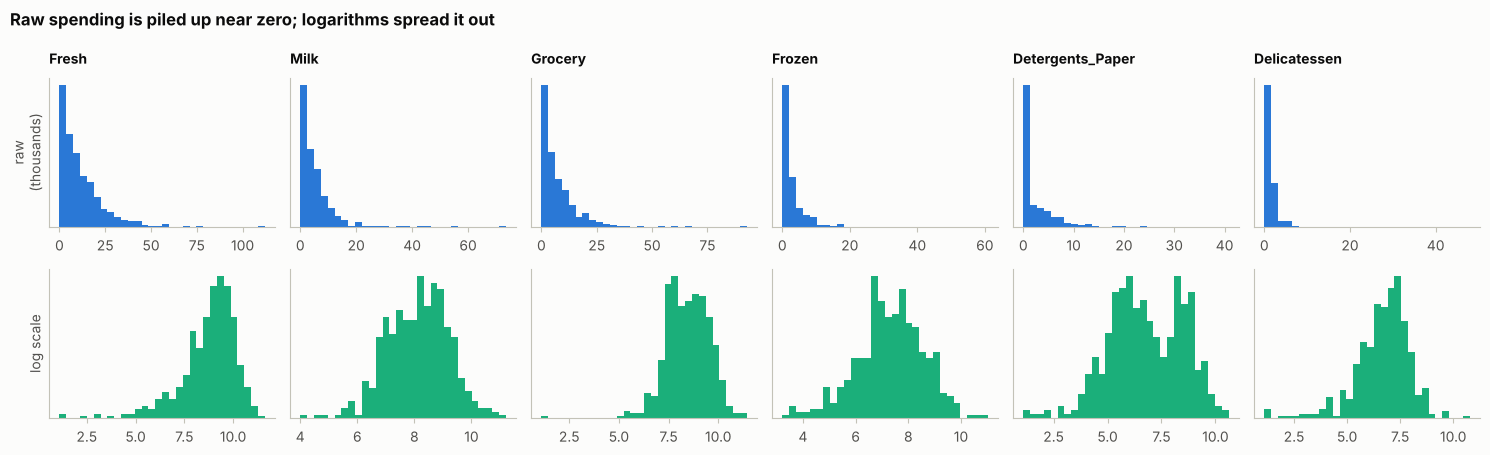

In [4]:
logged = np.log(customers[SPENDING])

fig, axes = plt.subplots(2, 6, figsize=(15, 4.6))
for i, column in enumerate(SPENDING):
    axes[0, i].hist(customers[column] / 1000, bins=30, color=PALETTE[0])
    axes[0, i].set_title(column, fontsize=10)
    axes[1, i].hist(logged[column], bins=30, color=PALETTE[2])
    for ax in axes[:, i]:
        ax.set_yticks([])
        ax.grid(False)
axes[0, 0].set_ylabel("raw\n(thousands)")
axes[1, 0].set_ylabel("log scale")
fig.suptitle("Raw spending is piled up near zero; logarithms spread it out", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

On the log scale, most categories look roughly bell-shaped. A few customers sit far out on the left: they spent almost nothing in that category (some as little as 3 monetary units in a year). We'll come back to them in Step 3.

Which categories go together?

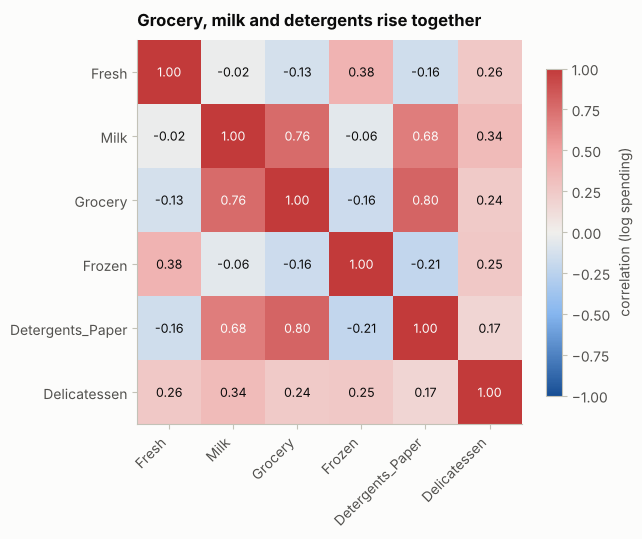

In [5]:
correlation = logged.corr()
fig, ax = plt.subplots(figsize=(6.2, 5))
image = ax.imshow(correlation, cmap=DIVERGING, vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(6), SPENDING, rotation=45, ha="right")
ax.set_yticks(range(6), SPENDING)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color=SURFACE if abs(correlation.iloc[i, j]) > 0.6 else INK)
fig.colorbar(image, ax=ax, label="correlation (log spending)", shrink=0.85)
ax.set_title("Grocery, milk and detergents rise together")
plt.show()

Two families stand out. **Grocery, Milk and Detergents_Paper** are strongly correlated: customers who buy a lot of one tend to buy a lot of the others. That's what a shop's shopping list looks like. **Fresh and Frozen** go together more weakly, which fits kitchens that cook meals. Delicatessen is mildly linked to everything.

For the rest of the project, the features are the log spending, **standardised** so each category counts equally:

In [6]:
from sklearn.preprocessing import StandardScaler

Z = StandardScaler().fit_transform(logged)
print(Z.shape, "  means:", Z.mean(axis=0).round(2), "  standard deviations:", Z.std(axis=0).round(2))

(440, 6)   means: [-0. -0. -0.  0.  0.  0.]   standard deviations: [1. 1. 1. 1. 1. 1.]


## Step 2: Map the customers with PCA

In [7]:
from sklearn.decomposition import PCA

pca = PCA().fit(Z)
loadings = pd.DataFrame(pca.components_, columns=SPENDING, index=[f"PC{i}" for i in range(1, 7)])
print("share of variance:", pca.explained_variance_ratio_.round(3))
print("cumulative:       ", np.cumsum(pca.explained_variance_ratio_).round(3))
print()
loadings.iloc[:3].round(2)

share of variance: [0.44  0.271 0.108 0.101 0.049 0.031]
cumulative:        [0.44  0.711 0.819 0.92  0.969 1.   ]



,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
PC1,-0.10,0.54,0.57,-0.14,0.55,0.21
PC2,0.59,0.13,-0.01,0.59,-0.07,0.53
PC3,-0.63,-0.08,-0.13,-0.03,-0.20,0.73


The first two components hold about 70% of the variation in the six categories:

- **PC1** loads on Grocery, Milk and Detergents_Paper: a "retail basket" axis. A customer with a high PC1 score spends a lot on those.
- **PC2** loads on Fresh, Frozen and Delicatessen: a "kitchen" axis.

So the six numbers mostly boil down to two questions: how much of the shop-type goods does a customer buy, and how much of the kitchen-type goods? Here are all 440 customers on those two axes, with no labels yet:

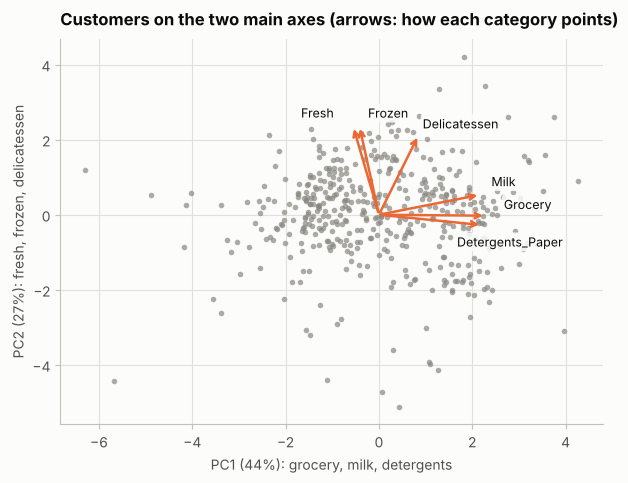

In [8]:
scores = pca.transform(Z)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(scores[:, 0], scores[:, 1], s=16, color=MUTED, alpha=0.7)
scale = 4
label_nudge = {"Fresh": (-0.9, 0.35), "Frozen": (0.75, 0.35), "Delicatessen": (0.9, 0.3),
               "Milk": (0.5, 0.35), "Grocery": (0.9, 0.3), "Detergents_Paper": (0.6, -0.45)}
for column, (x, y) in zip(SPENDING, pca.components_[:2].T):
    ax.annotate("", xy=(x * scale, y * scale), xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": PALETTE[1], "lw": 1.8})
    dx, dy = label_nudge[column]
    ax.text(x * scale + dx, y * scale + dy, column, color=INK, fontsize=9, ha="center", va="center",
            bbox={"boxstyle": "round,pad=0.15", "facecolor": SURFACE, "edgecolor": "none", "alpha": 0.85})
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%}): grocery, milk, detergents")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%}): fresh, frozen, delicatessen")
ax.set_title("Customers on the two main axes (arrows: how each category points)")
plt.show()

This kind of plot, with arrows for the original features, is called a **biplot**. The arrows show the direction in which each category increases: Grocery, Milk and Detergents point right, Fresh and Frozen point up.

There's no obvious gap that splits the customers into separate islands. The cloud looks more like one continuous spread, a little denser on the left. Keep that in mind: whatever groups we find, they may be regions of a continuum rather than truly separate types.

## Step 3: Flag unusual customers

Before clustering, it's worth finding customers who don't fit the general pattern. They can pull centroids around, and they're interesting in their own right. Three methods from the lesson:

In [9]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

median = logged.median()
mad = (logged - median).abs().median()
robust_z = (logged - median) / (1.4826 * mad)

flags = pd.DataFrame({
    "isolation forest": -IsolationForest(random_state=0).fit(Z).score_samples(Z),
    "local outlier factor": -LocalOutlierFactor(n_neighbors=20).fit(Z).negative_outlier_factor_,
    "largest |robust z|": robust_z.abs().max(axis=1),
}, index=customers.index)
ranks = flags.rank(ascending=False)
flags["average rank"] = ranks.mean(axis=1)
top = flags.sort_values("average rank").head(8).index

print("the 8 customers the methods agree are most unusual:")
customers.loc[top, ["Channel"] + SPENDING].join(flags.loc[top, "largest |robust z|"].round(1))

the 8 customers the methods agree are most unusual:


,Channel,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,largest |robust z|
338,Horeca,3,333,7021,15601,15,550,7.1
75,Horeca,20398,1137,3,4407,3,975,6.2
154,Horeca,622,55,137,75,7,8,4.5
142,Horeca,37036,7152,8253,2995,20,3,5.4
66,Horeca,9,1534,7417,175,3468,27,6.1
183,Horeca,36847,43950,20170,36534,239,47943,3.7
95,Horeca,3,2920,6252,440,223,709,7.1
218,Retail,18,7504,15205,1285,4797,6372,5.5


The three methods broadly agree on the most unusual customers. Reading their spending explains why: most of them bought almost nothing in one or two categories (a handful of monetary units in a whole year) while spending normally elsewhere. On the log scale those tiny amounts are extreme. One of them (customer 183) is unusual the other way: a very large customer who spends heavily in every category.

Are these errors? We can't tell from the data. A café that buys its fresh food from someone else would spend almost nothing on Fresh with this distributor, which is entirely plausible. They might also be new customers who joined late in the year, or recording mistakes. With no way to check, the sensible approach is:

- **Keep them** in the analysis (deleting real customers because they're unusual would bias the results).
- **Check** that the conclusions don't depend on them: rerun the clustering without the most unusual 5% and compare (Step 6).
- **Report them** to the business as worth a look: an outlier list is often one of the most useful outputs of an analysis like this.

## Step 4: How many groups?

Four tools, for k from 2 to 8:

- **inertia** (the elbow method) and **average silhouette** for k-means
- **BIC** for Gaussian mixtures
- **stability**: the average adjusted Rand index between the k-means clustering of all customers and clusterings of bootstrap samples

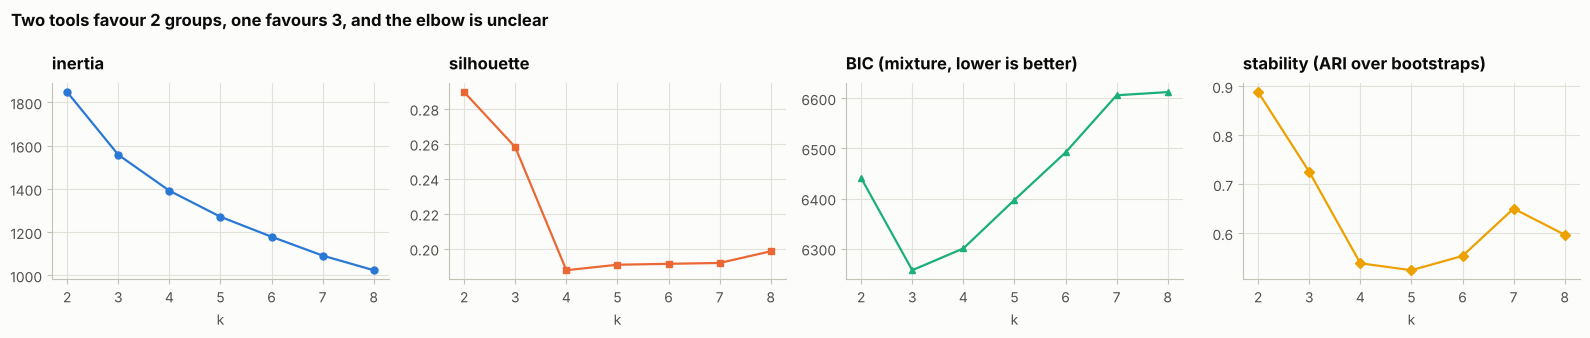

,inertia,silhouette,BIC (mixture),stability
k,,,,
2,1847.995,0.290,6440.824,0.888
3,1558.047,0.258,6257.020,0.725
4,1391.926,0.188,6300.460,0.539
5,1271.279,0.191,6397.271,0.525
6,1178.992,0.191,6492.017,0.554
7,1091.825,0.192,6606.143,0.650
8,1024.226,0.199,6612.449,0.597


In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture


def stability(X, k, n_boot=30, seed=0):
    rng = np.random.default_rng(seed)
    reference = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    aris = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(X), len(X))
        resampled = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X[idx])
        aris.append(adjusted_rand_score(reference.labels_, resampled.predict(X)))
    return np.mean(aris)


rows = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    rows[k] = {"inertia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
               "BIC (mixture)": GaussianMixture(n_components=k, n_init=5, random_state=0).fit(Z).bic(Z),
               "stability": stability(Z, k)}
choice = pd.DataFrame(rows).T
choice.index.name = "k"

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, column, colour, marker in zip(axes, choice.columns, PALETTE, ["o", "s", "^", "D"]):
    ax.plot(choice.index, choice[column], color=colour, marker=marker, markersize=5)
    ax.set_xlabel("k")
    ax.set_title(column)
axes[2].set_title("BIC (mixture, lower is better)")
axes[3].set_title("stability (ARI over bootstraps)")
fig.suptitle("Two tools favour 2 groups, one favours 3, and the elbow is unclear", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()
choice.round(3)

What the four tools say:

- **The elbow is unclear.** Inertia falls smoothly, with only a mild bend at 2 or 3. No obvious answer.
- **The silhouette is highest at k = 2**, but at about 0.29 it's low. Silhouettes below about 0.25 to 0.3 are usually read as weak structure: the groups overlap a lot. That matches the PCA map, with no clear gaps.
- **The BIC prefers 3 components**, though the values for 2 to 5 aren't far apart.
- **Stability is clearly highest at k = 2**: two groups come back almost the same way on almost every bootstrap sample. From 3 groups upwards, the boundaries shift noticeably from sample to sample.

The honest summary: these customers don't fall into sharply separated types. There is one fairly dependable division into **two** broad groups. Finer divisions can be made, and may still be useful for planning, but they're less certain, and an analyst should say so rather than present them as natural categories.

We'll describe the two-group solution carefully, then look at three groups as a finer, less certain view.

## Step 5: Describe the groups

In [11]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=0).fit(Z)
labels2 = km2.labels_


def profile(labels):
    """Size and median annual spending of each group, in the original units."""
    groups = pd.Series(labels, index=customers.index, name="group")
    table = customers[SPENDING].groupby(groups).median()
    table.insert(0, "customers", groups.value_counts().sort_index())
    return table


profile(labels2).round(0)

,customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
group,,,,,,,
0,251,10290.0,1860.0,2406.0,2234.0,325.0,750.0
1,189,5417.0,7677.0,11522.0,1059.0,4482.0,1386.0


Reading the medians in the original units:

- **One group** spends heavily on **Grocery, Milk and Detergents_Paper**, typically several times as much as the other group, and less on Fresh and Frozen. This is the profile of a **shop**.
- **The other group**, which is larger, spends more on **Fresh and Frozen** and very little on Detergents_Paper. This is the profile of a **kitchen**: restaurants, hotels and cafés.

Here are the groups on the PCA map, which shows that the split runs mainly along PC1, the retail-basket axis:

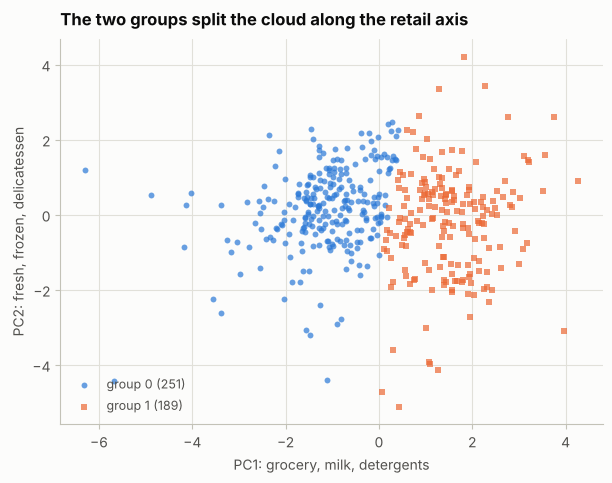

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
for j, (marker, name) in enumerate(zip(["o", "s"], ["group 0", "group 1"])):
    mask = labels2 == j
    ax.scatter(scores[mask, 0], scores[mask, 1], s=18, color=PALETTE[j], marker=marker, alpha=0.7, label=f"{name} ({mask.sum()})")
ax.set_xlabel("PC1: grocery, milk, detergents")
ax.set_ylabel("PC2: fresh, frozen, delicatessen")
ax.legend(loc="lower left", fontsize=9)
ax.set_title("The two groups split the cloud along the retail axis")
plt.show()

## Step 6: Check the groups

### Against the channel

We kept the channel aside. Now we can ask: do the two spending groups match the two kinds of business?

In [13]:
print(pd.crosstab(pd.Series(labels2, name="group"), customers["Channel"]).to_string())
print(f"\nadjusted Rand index with the channel: {adjusted_rand_score(customers['Channel'], labels2):.3f}")
print(f"region, for comparison:              {adjusted_rand_score(customers['Region'], labels2):.3f}")

Channel  Horeca  Retail
group                  
0           244       7
1            54     135

adjusted Rand index with the channel: 0.520
region, for comparison:              -0.008


Strongly, though not perfectly. Nearly all of the kitchen-like group are Horeca customers (244 of 251), and most of the shop-like group are retail customers (135 of 189). The clustering, which never saw the channel, rediscovered the main division in the business from spending alone. The groups have nothing to do with region (ARI about 0).

The mismatches are interesting in themselves. 54 Horeca customers buy like shops (perhaps hotels with their own shops, or caterers who resell), and only 7 retail customers buy like kitchens (perhaps delicatessens or butchers). Those are exactly the customers a sales team would want to look at more closely.

### Against other methods

Groups that only one algorithm finds are less trustworthy than groups several algorithms agree on:

In [14]:
from sklearn.cluster import AgglomerativeClustering

alternatives = {
    "Gaussian mixture": GaussianMixture(n_components=2, n_init=5, random_state=0).fit(Z).predict(Z),
    "hierarchical (Ward)": AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(Z),
    "hierarchical (average)": AgglomerativeClustering(n_clusters=2, linkage="average").fit_predict(Z),
}
for name, labels in alternatives.items():
    sizes = np.bincount(labels)
    print(f"{name:<24} sizes {str(sizes):<12} ARI with k-means {adjusted_rand_score(labels2, labels):.2f}   with channel {adjusted_rand_score(customers['Channel'], labels):.2f}")

Gaussian mixture         sizes [274 166]    ARI with k-means 0.69   with channel 0.62
hierarchical (Ward)      sizes [206 234]    ARI with k-means 0.63   with channel 0.42
hierarchical (average)   sizes [  2 438]    ARI with k-means -0.00   with channel -0.00


The methods agree only partly, and the differences are instructive:

- **Ward** linkage, which looks for compact groups like k-means does, finds a similar but not identical split.
- **Average** linkage doesn't find two balanced groups at all: it splits off a few unusual customers and leaves everyone else together. That's what it does when there's no clear gap: the most isolated points are the "most different" cluster.
- The **Gaussian mixture**, free to choose elliptical groups of different sizes, finds a somewhat different split, with more customers in the kitchen-like group. It happens to match the channel even more closely than k-means does.

This confirms the picture from Step 4: the two-group division is a reasonable way to cut a continuous cloud, found by methods that look for compact groups, rather than two separate islands that every method would find.

### Without the unusual customers

Finally, does the result depend on the outliers from Step 3? Remove the 5% most unusual customers, cluster again, and compare on the customers that remain:

In [15]:
keep = flags["average rank"] > flags["average rank"].quantile(0.05)
km_trimmed = KMeans(n_clusters=2, n_init=10, random_state=0).fit(Z[keep.to_numpy()])
print(f"customers kept: {keep.sum()} of {len(keep)}")
print(f"ARI with the original two groups, on the kept customers: {adjusted_rand_score(labels2[keep.to_numpy()], km_trimmed.labels_):.3f}")

customers kept: 418 of 440
ARI with the original two groups, on the kept customers: 0.943


The two groups are almost unchanged without the unusual customers, so they aren't an artefact of a few odd records.

### A finer view: three groups

The BIC suggested three components. Here's what three k-means groups look like, with the stability caveat from Step 4 in mind:

In [16]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z)
table3 = profile(km3.labels_)
table3["Retail share"] = pd.crosstab(km3.labels_, customers["Channel"], normalize="index")["Retail"].to_numpy()
print(f"stability of k = 3: {choice.loc[3, 'stability']:.2f}   (k = 2: {choice.loc[2, 'stability']:.2f})")
table3.round(2)

stability of k = 3: 0.73   (k = 2: 0.89)


,customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,Retail share
group,,,,,,,,
0,81,1454.0,6264.0,10487.0,388.0,4196.0,436.0,0.59
1,148,12165.5,7146.0,9879.5,2019.0,3349.5,1987.5,0.61
2,211,9612.0,1596.0,2147.0,2121.0,274.0,686.0,0.01


With three groups, the kitchen-like customers stay together (and are almost all Horeca), while the shop-like customers split into two: customers who buy grocery-type goods and very little fresh, frozen or delicatessen, and large customers who buy a lot of everything. Both of these are a mix of retail and Horeca customers. That might be a useful distinction, for example for deciding which customers to offer a wider range to. But the three-group split is noticeably less stable than the two-group one, so it should be presented as one reasonable way to subdivide the shop-like customers, not as three natural types.

### A t-SNE map

A t-SNE map gives one more view, coloured by the two groups and, separately, by the channel:

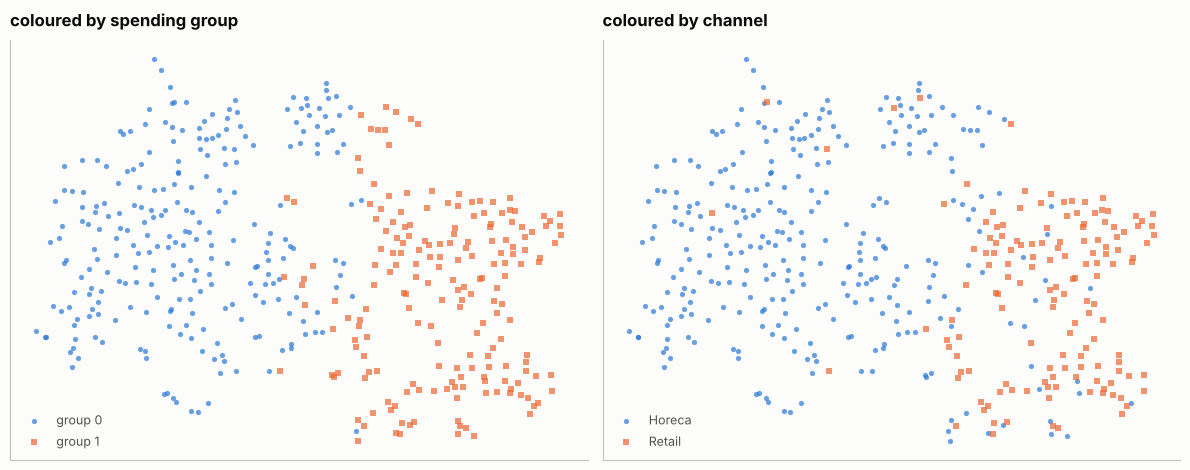

In [17]:
from sklearn.manifold import TSNE

coords = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, labels, names, title in [(axes[0], labels2, ["group 0", "group 1"], "coloured by spending group"),
                                  (axes[1], (customers["Channel"] == "Retail").astype(int).to_numpy(), ["Horeca", "Retail"], "coloured by channel")]:
    for j, marker in zip(range(2), ["o", "s"]):
        ax.scatter(coords[labels == j, 0], coords[labels == j, 1], s=14, color=PALETTE[j], marker=marker, alpha=0.7, label=names[j])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(loc="lower left", fontsize=9)
    ax.set_title(title)
fig.tight_layout()
plt.show()

The t-SNE map shows the same thing as the PCA map, in a different way: one large connected cloud, with the groups occupying different ends of it and mixing where they meet. The channel follows the same layout, which is why the groups match it so well. (As the lesson warned, distances and sizes on a t-SNE map shouldn't be read too literally.)

## What to tell the distributor

**What the analysis supports:**

- Customers' spending varies along two main dimensions: how much they buy of **shop-type goods** (grocery, milk, detergents and paper) and how much of **kitchen-type goods** (fresh, frozen, delicatessen).
- There's one dependable division into **two broad groups**, "shop-like" and "kitchen-like". It's stable under resampling, unaffected by unusual customers, and matches the recorded channel for most customers. It was found from spending alone.
- The **customers who buy against type** (Horeca customers who buy like shops, and the reverse) and the **unusual customers** from Step 3 are worth a closer look by the sales team.

**What it doesn't support:**

- **Sharply separated customer types.** The silhouette is low, different algorithms split the customers differently, and the maps show a continuous cloud. Any finer segmentation, such as the three groups, is a convenient way of dividing a continuum, and should be chosen by whether it's useful, not presented as a discovery.
- **Causes or value.** The data is one year of spending with one distributor. It says nothing about why customers buy what they buy, how much they spend with competitors, or how profitable each customer is.

**Limits of the data:** 440 customers, mostly outside Lisbon and Oporto, one year, and the currency isn't stated. A segmentation built here should be tested on more recent data before it's used for decisions.

A useful next step would be the test from the lesson's section 11: try a different service or offer for each group and **measure** whether it works better than treating everyone the same.

## What we learned

- **Skewed amounts need a log transform** before distance-based methods; otherwise a few big customers dominate.
- **PCA** reduced six spending categories to two interpretable axes, a retail basket and a kitchen basket, holding about 70% of the variation.
- **Unusual customers** were flagged by three methods that broadly agreed. They were kept, reported, and shown not to change the result.
- **Choosing k** with four tools gave a mixed picture: two groups were clearly the most stable and had the best silhouette, but the silhouette was low and the BIC preferred three. The honest conclusion was weak structure with one dependable division.
- **External checks** made the result credible: the two groups matched the business channel (ARI about 0.5) without ever seeing it, and had nothing to do with region.
- **Different algorithms disagreed**, which is itself evidence that the groups are regions of a continuum rather than separate islands.

### Ideas to go further

1. Use `Region` and `Channel` as well as spending, with one-hot encoding. How does the clustering change? Is that a better or worse segmentation for the distributor?
2. Cluster on **shares** of spending (each category as a fraction of the customer's total) instead of amounts. That separates "what a customer buys" from "how much". Which matters more for the groups?
3. Try `HDBSCAN` from `sklearn.cluster`. Does it find any dense groups, or call most customers noise?
4. Replace the bootstrap stability check with one based on **subsamples** of 80% of the customers drawn without replacement. Do the conclusions change?
5. Write a short function that takes a new customer's spending and returns its group and how unusual it is, using the fitted scaler, k-means model and Isolation Forest. That's the first step to using the segmentation in practice.

Data: Cardoso, M. (2013). Wholesale customers. UCI Machine Learning Repository. https://doi.org/10.24432/C5030X, licensed under CC BY 4.0.